# Filtrul Bayes

Filtrul Bayes este o metoda recusiva de estimare a unei distributii de probabilitate. In robotica, filtrele Bayes sunt des folosite pentru a estima pozitia si orientarea. 

Notam starea sistemului la momentul k cu $\mathbf{x}_k$, continand variabilele de interes ale robotului (ex. pozitie in plan (x,y) si orientarea ).
$$\mathbf{x}_k = \begin{bmatrix} x_k \\ y_k \\ \theta_k \end{bmatrix}$$

Notam cu $p(\mathbf{x}_k \mid \mathbf{z}_{1:k})$ distributia probabilitatii ca robotul sa se afle in starea $\mathbf{x}_k$, conditionata de masuratorile colectate pana la momentul respectiv. Daca nu avem nici o informatie initiala, putem considera distibutia uniforma <br>
<p align="center">
  <img src="media/dist_unif.png" alt="Distribytie uniforma" width="800">
</p>

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from IPython.display import display, clear_output

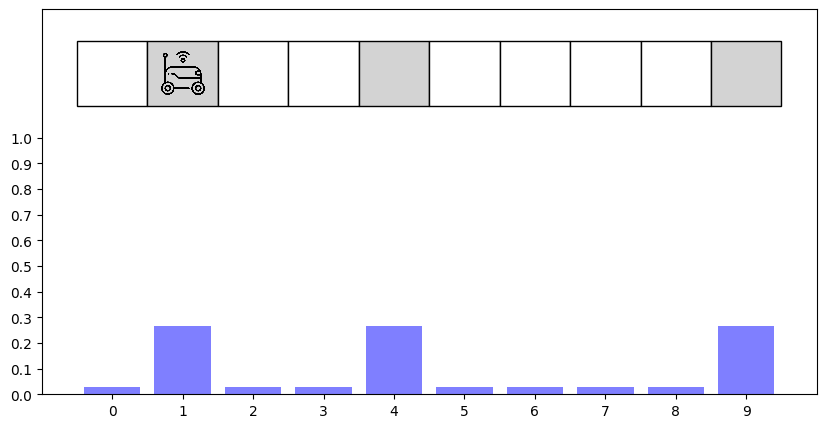

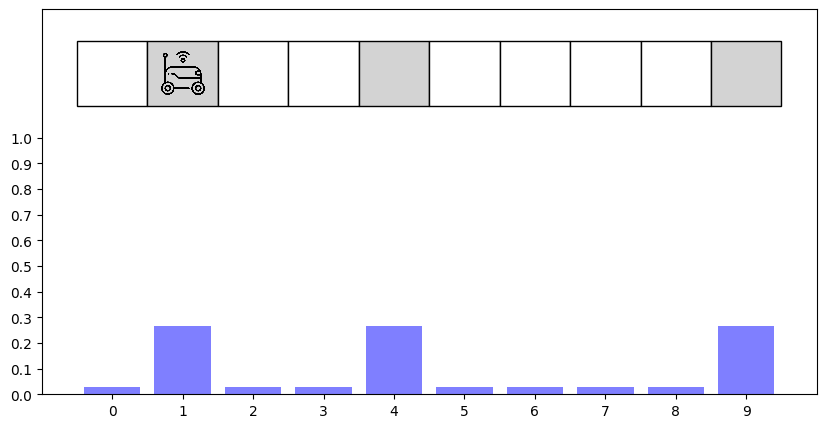

In [24]:
# Visual Parameters
cell_width = 1
cell_height = 0.25

# Demo Parameters
map_ = [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
prob = np.full(len(map_), 1.0/len(map_), dtype=np.float32)
prob_hit = 0.75
prob_miss = 1.0 - prob_hit
measurements = [1, 1, 1, 0]
robot_index = 1

fig, ax = plt.subplots(figsize=(10, 5))

# Draw the map
for i in range(len(map_)):
    if map_[i]:
        color = 'lightgray'
    else:
        color = 'white'
    square = mpatches.Rectangle((i * cell_width - cell_width/2, 1.25-cell_height/2), cell_width, cell_height, facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(square)

# Draw the probability bars
bars = ax.bar(range(len(prob)), prob, color='blue', alpha=0.5, label='Probability')
ax.set_ylim(0,1.5)
ax.set_xticks(range(len(map_)))
ax.set_yticks(np.arange(0, 1.1, 0.1))

# Draw the robot icon
robot_icon = mpimg.imread('media/robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
ax.add_artist(AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False))

display(fig)

# Update the probabilities based on measurements
for m in measurements:
    for i in range(len(prob)):
        if map_[i] == m:
            prob[i] *= prob_hit
        else:
            prob[i] *= prob_miss

    prob /= np.sum(prob)
    

    input("Press Enter for a new measure...")

    for bar, z in zip(bars, prob):
        bar.set_height(z)
    clear_output(wait=True)
    display(fig)


# Model de Miscare

O modalitate de a deduce pozitia in timp este pe baza de comenzi catre robot. Metoda se numeste "Dead Reckoning" si are ca baza un model matematic ce descrie legatura dintre comanda si evolutia starii. Comanda se noteaza in mod uzual cu $\mathbf{u}_{k}$ si rezultatul obtinut din aceasta metoda se noteaza $p(\mathbf{x}_k \mid \mathbf{u}_{1:k-1})$.

Modele folosite uzual sunt o aproximare a dinaminii procesului real. De aceea, in prezicerea pozitiei viitoare pe se adauga o incertitudine in calcule, denumita "zgomot de proces". Acest zgomot reprezinta variabile lipsite din model (ex vant, forte de frecare, intarzieri ale comenzii, zgomot electric, etc. ).

In [ ]:
def shift_prob(arr, dir, prob_hit, prob_miss):
    new_prob = np.zeros_like(arr)
    for i in range(len(arr)):
        new_prob[i] = arr[(i + dir) % len(arr)] * prob_hit + arr[i] * prob_miss
    return new_prob

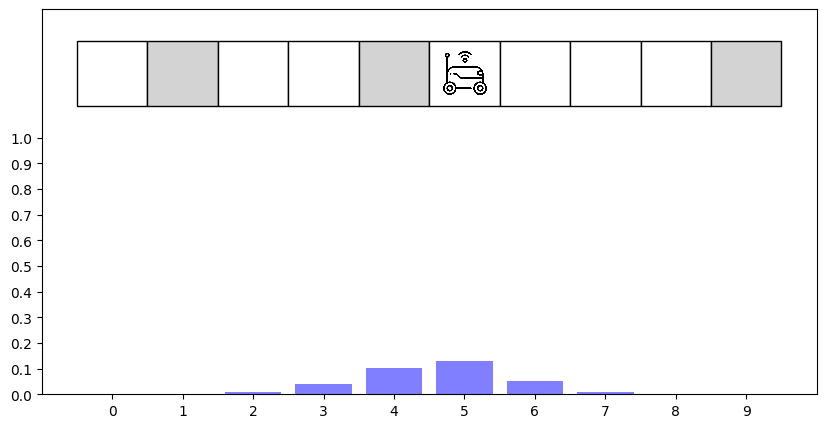

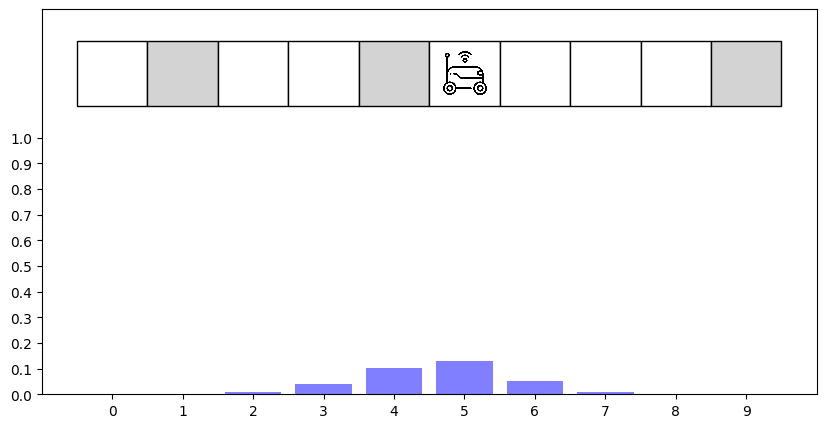

In [4]:
map_ = [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
prob = np.zeros_like(map_, dtype=np.float32)
cell_width = 1
cell_height = 0.25
motion_prob = 0.8
miss_prob = (1.0 - motion_prob)/2
robot_index = 1

fig, ax = plt.subplots(figsize=(10, 5))

# Draw the map
for i in range(len(map_)):
    if map_[i]:
        color = 'lightgray'
    else:
        color = 'white'
    square = mpatches.Rectangle((i * cell_width - cell_width/2, 1.25-cell_height/2), cell_width, cell_height, facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(square)

# Draw the probability bars
prob[robot_index] = motion_prob
prob[(robot_index - 1) % len(map_)] = miss_prob
prob[(robot_index + 1) % len(map_)] = miss_prob

bars = ax.bar(range(len(prob)), prob, color='blue', alpha=0.5, label='Probability')
ax.set_ylim(0,1.5)
ax.set_xticks(range(len(map_)))
ax.set_yticks(np.arange(0, 1.1, 0.1))

# Draw the robot icon
robot_icon = mpimg.imread('robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
ax.add_artist(annot)
display(fig)

while True:
    key = input("Press 'a' or 'd' to move the robot, or 'q' to quit...")

    if key == 'q':
        break
    elif key == 'a':
        dir = 1
    elif key == 'd':
        dir = -1

    prob = shift_prob(prob, dir, motion_prob, miss_prob)
    robot_index = (robot_index - dir) % len(map_)

    annot.remove()
    annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
    ax.add_artist(annot)

    for bar, z in zip(bars, prob):
            bar.set_height(z)
    clear_output(wait=True)
    display(fig)


# Predict and Update

Avand un model atat pentru senzot cat si pentru miscare, putem aplica algoritmul in mod iterativ. La fiecare esantionare a senzorului, se calculeaza "cum a evoluat distributia cat timp nu au fost facute masurat?", iar noua masuratoare se aplica pentru corectie.

$$p(\mathbf{x}_k \mid \mathbf{z}_{1:k}) = \frac{p(\mathbf{z}_k \mid \mathbf{x}_k) \, p(\mathbf{x}_k \mid \mathbf{z}_{1:k-1}, \mathbf{u}_{1:k})}{p(\mathbf{z}_k)}$$

In mod uzual, numitorul este doar un termen de normalizare si nu este calculat implicit. El reprezinta probabilitate de a avea o anumita masuratoare lunad in calcul toate posibilile stari ale robotului.

In [ ]:
from scipy.stats import bernoulli

def measure(prob, map_, robot_index, prob_hit):

    if map_[robot_index] == 1:
        p = prob_hit
    else:
        p = 1 - prob_hit
    
    measurement = bernoulli.rvs(p, size=1)[0]

    for i in range(len(prob)):
        if map_[i] == measurement:
            prob[i] *= prob_hit
        else:
            prob[i] *= prob_miss
    prob /= np.sum(prob)
    return prob

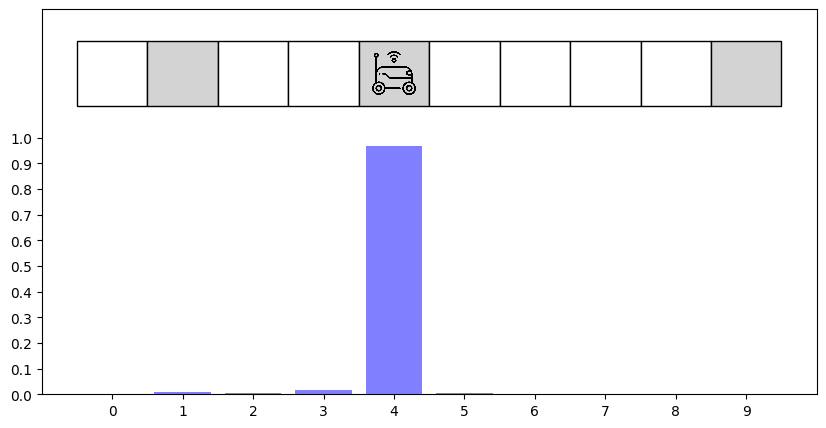

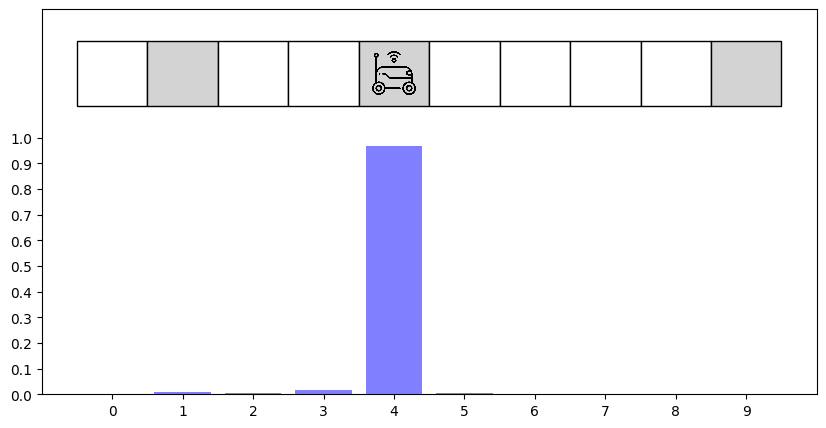

In [ ]:
map_ = [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
prob = np.zeros_like(map_, dtype=np.float32)
cell_width = 1
cell_height = 0.25
motion_prob = 0.8
miss_prob = (1.0 - motion_prob)/2
robot_index = 1

prob_hit = 0.75
prob_miss = 1.0 - prob_hit

fig, ax = plt.subplots(figsize=(10, 5))

# Draw the map
for i in range(len(map_)):
    if map_[i]:
        color = 'lightgray'
    else:
        color = 'white'
    square = mpatches.Rectangle((i * cell_width - cell_width/2, 1.25-cell_height/2), cell_width, cell_height, facecolor=color, edgecolor='black', linewidth=1)
    ax.add_patch(square)

# Draw the probability bars
prob[robot_index] = motion_prob
prob[(robot_index - 1) % len(map_)] = miss_prob
prob[(robot_index + 1) % len(map_)] = miss_prob

bars = ax.bar(range(len(prob)), prob, color='blue', alpha=0.5, label='Probability')
ax.set_ylim(0,1.5)
ax.set_xticks(range(len(map_)))
ax.set_yticks(np.arange(0, 1.1, 0.1))

# Draw the robot icon
robot_icon = mpimg.imread('robot.png')
imagebox = OffsetImage(robot_icon, zoom=0.075)
annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
ax.add_artist(annot)
display(fig)

while True:
    key = input("Press 'a' or 'd' to move the robot, 's' to measure or 'q' to quit...")

    dir = None

    if key == 'q':
        break
    elif key == 'a':
        dir = 1
    elif key == 'd':
        dir = -1
    elif key == 's':
        dir = 0

    if dir:
        prob = shift_prob(prob, dir, motion_prob, miss_prob)
        robot_index = (robot_index - dir) % len(map_)

        annot.remove()
        annot = AnnotationBbox(imagebox, (robot_index, 1.25), frameon=False)
        ax.add_artist(annot)
    elif dir == 0:
        prob = measure(prob, map_, robot_index, prob_hit)

    for bar, z in zip(bars, prob):
            bar.set_height(z)
    clear_output(wait=True)
    display(fig)


# TODO

Extindeti exemplul 1D la unul 2D. Dezvolati urmatoarele componente:
* Model de senzor
* Model de miscare
* Pas de predictie
* Pas de corectie
* O convergenta sesizabila a increderii in pozitiei